In [2]:
from google.colab import files
uploaded = files.upload()

import pandas as pd

cars = pd.read_csv("CarDetails.csv")

display(cars.head())
print("Rows and columns:", cars.shape)
print("Missing values:\n", cars.isna().sum())
print("Exact duplicate rows:", cars.duplicated().sum())
print(f"Average selling price: {cars['selling_price'].mean():,.2f}")
print(f"Median selling price: {cars['selling_price'].median():,.2f}")
print("Records by fuel type:\n", cars["fuel"].value_counts())

Saving CarDetails.csv to CarDetails.csv


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


Rows and columns: (4340, 8)
Missing values:
 name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64
Exact duplicate rows: 763
Average selling price: 504,127.31
Median selling price: 350,000.00
Records by fuel type:
 fuel
Diesel      2153
Petrol      2123
CNG           40
LPG           23
Electric       1
Name: count, dtype: int64


Diesel has the most records, with 2,153 out of 4,340.


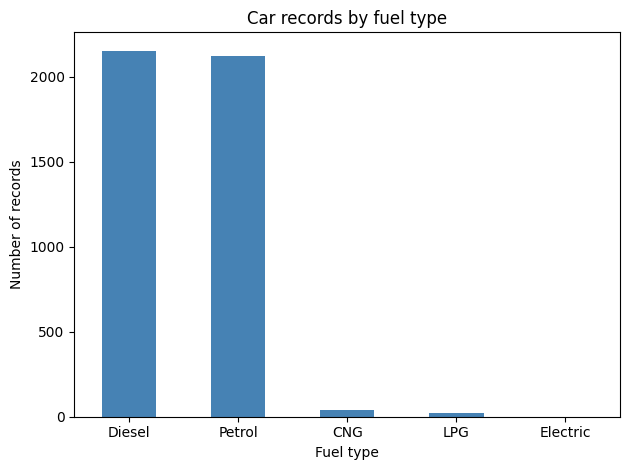

In [3]:
import matplotlib.pyplot as plt

fuel_counts = cars["fuel"].value_counts()
top_fuel = fuel_counts.idxmax()
top_count = fuel_counts.max()

print(f"{top_fuel} has the most records, with {top_count:,} out of {len(cars):,}.")

ax = fuel_counts.plot(kind="bar", color="steelblue", rot=0)
ax.set(title="Car records by fuel type", xlabel="Fuel type", ylabel="Number of records")
plt.tight_layout()
plt.show()

In [8]:
%pip install "google-genai>=2.12.1,<3" "google-auth==2.49.0"

INFO: pip is looking at multiple versions of google-genai to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of google-genai to determine which version is compatible with other requirements. This could take a while.
INFO: This is taking longer than usual. You might need to provide the dependency resolver with stricter constraints to reduce runtime. See https://pip.pypa.io/warnings/backtracking for guidance. If you want to abort this run, press Ctrl + C.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 11.0 MB/s  0:00:00
  Attempting uninstall: google-auth
    Found existing installation: google-auth 2.63.1
    Uninstalling google-auth-2.63.1:
      Successfully uninstalled google-auth-2.63.1
  Attempting uninstall: google-genai
    Found existing installation: google-genai 3.6.1
    Uninstalling google-genai-3.6.1:
      Successfully uninstalled google-genai-3.6.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━

In [13]:
from google.colab import userdata
from google import genai

client = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))

MODEL = "gemini-3.5-flash-lite"
print("Gemini model:", MODEL)

Gemini model: gemini-3.5-flash-lite


In [10]:
%%writefile car_assistant.py
import json

import matplotlib.pyplot as plt
import pandas as pd
from google.genai import types


PROMPTS = {
    "V1": "Choose an operation and column that answer the question.",
    "V2": """
You are planning an analysis of a used-car dataset. Use exact column names.
Use mean or median only for numeric columns. If the required column is absent,
return unsupported. If the question depends on an unclear metric, return
clarify and include a specific question for the user.
""",
    "V3": """
Plan the calculation for Pandas. Interpret the question using the schema,
then select one supported operation. Pandas will calculate the result.

Examples:
"Which fuel type appears most often?"
{"operation":"most_common","column":"fuel","message":""}

"Compare median prices by transmission."
{"operation":"median_by_group","column":"selling_price",
 "group_by":"transmission","message":""}

"Which car is best?"
{"operation":"clarify","message":"Do you mean lowest price or lowest kilometres driven?"}

"What's the average engine size?"
{"operation":"unsupported","message":"The dataset has no engine size column."}

Treat year as the car's model year. Use exact column names. Return clarify
for ambiguous criteria and unsupported for missing fields or operations.
""",
}

NUMERIC_OPERATIONS = {"mean", "median", "median_by_group"}
OPERATIONS = NUMERIC_OPERATIONS | {
    "row_count", "missing_values", "duplicate_count",
    "count_by", "most_common", "clarify", "unsupported",
}


def gemini_text(client, model, prompt, structured=False):
    config = types.GenerateContentConfig(
        temperature=0,
        response_mime_type="application/json" if structured else None,
    )
    response = client.models.generate_content(
        model=model, contents=prompt, config=config
    )
    if not response.text:
        raise RuntimeError("Gemini returned an empty response.")
    return response.text


def make_plan(df, question, client, model, version="V3"):
    schema = {column: str(dtype) for column, dtype in df.dtypes.items()}
    prompt = f"""
{PROMPTS[version]}

Columns and types: {json.dumps(schema)}
Question: {json.dumps(question)}
Available operations: {", ".join(sorted(OPERATIONS))}

Return one JSON object with operation, column, group_by, and message.
Leave unused fields blank or omit them. Use column for the field to count
or summarize. Use group_by only with median_by_group. Use message for
clarify and unsupported.
"""
    plan = json.loads(gemini_text(client, model, prompt, structured=True))
    if not isinstance(plan, dict):
        raise ValueError("Gemini returned an invalid analysis plan.")
    return plan


def calculate(df, plan):
    operation = plan.get("operation")
    column = plan.get("column")
    group_by = plan.get("group_by")

    if not isinstance(operation, str) or operation not in OPERATIONS:
        raise ValueError("The analysis plan contains an unsupported operation.")

    if operation in {"clarify", "unsupported"}:
        return str(plan.get("message") or "Please rephrase your question.")

    if operation == "row_count":
        return int(len(df))
    if operation == "duplicate_count":
        return int(df.duplicated().sum())
    if operation == "missing_values":
        return df.isna().sum().rename("Missing values")

    if not isinstance(column, str) or column not in df.columns:
        raise ValueError(f"The requested column is unavailable: {column}")
    if operation in NUMERIC_OPERATIONS and not pd.api.types.is_numeric_dtype(df[column]):
        raise ValueError(f"{column} must be numeric for this operation.")

    if operation == "mean":
        return float(df[column].mean())
    if operation == "median":
        return float(df[column].median())
    if operation == "median_by_group":
        if not isinstance(group_by, str) or group_by not in df.columns:
            raise ValueError(f"The grouping column is unavailable: {group_by}")
        return df.groupby(group_by)[column].median().dropna().sort_index()

    counts = df[column].value_counts()
    if operation == "most_common":
        if counts.empty:
            return counts
        return counts[counts.eq(counts.max())]
    return counts


def explain_result(question, plan, result, client, model):
    operation = plan["operation"]
    if operation in {"clarify", "unsupported"}:
        return result
    if isinstance(result, pd.Series):
        if result.empty:
            return "There are no values available for that analysis."
        evidence = result.head(20).to_string()
        if len(result) > 20:
            evidence += f"\nShowing 20 of {len(result)} groups."
    else:
        if pd.isna(result):
            return "There are no numeric values available for that calculation."
        evidence = f"{result:,.2f}" if isinstance(result, float) else str(result)

    prompt = f"""
Answer the user's question in one or two sentences using only the Pandas result.
Keep the numbers faithful to the result and do not assume a currency.
If several categories tie for first, mention the tie.

Question: {json.dumps(question)}
Analysis plan: {json.dumps(plan)}
Pandas result:
{evidence}
"""
    return gemini_text(client, model, prompt)


def make_chart(plan, result):
    operation = plan.get("operation")
    if operation not in {"count_by", "median_by_group"} or result.empty:
        return None

    if operation == "median_by_group" and plan.get("group_by") == "year":
        ax = result.plot(kind="line", marker="o", figsize=(9, 4))
        ax.set(xlabel="Model year", ylabel=f"Median {plan['column']}")
    else:
        chart_data = result.sort_values(ascending=False).head(15)
        ax = chart_data.plot(kind="bar", color="steelblue", figsize=(9, 4))
        label = "Record count" if operation == "count_by" else f"Median {plan['column']}"
        ax.set(ylabel=label)
        if len(result) > 15:
            ax.set_title("Top 15 groups")
        ax.tick_params(axis="x", labelrotation=35)

    figure = ax.get_figure()
    figure.tight_layout()
    return figure

Overwriting car_assistant.py


Ask a question about CarDetails.csv: How does median selling price vary by model year?
Analysis plan: {'operation': 'median_by_group', 'column': 'selling_price', 'group_by': 'year', 'message': ''}

Pandas result


,selling_price
year,
1992,50000.0
1995,95000.0
1996,225000.0
1997,79000.0
1998,60000.0
1999,65000.0
2000,63000.0
2001,69000.0
2002,80000.0


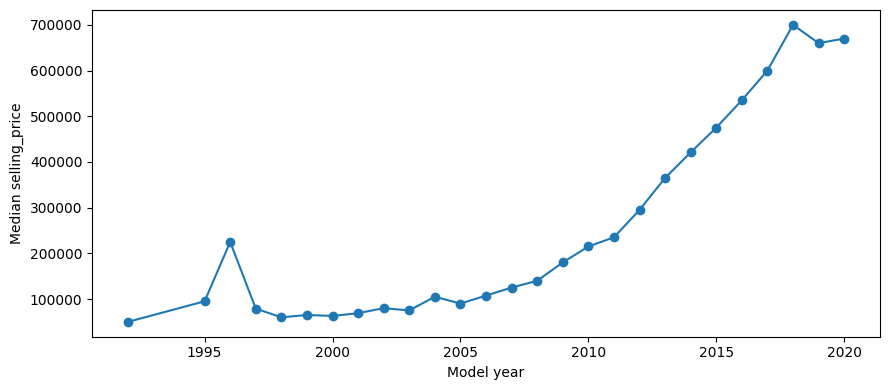


Assistant answer
The median selling price varies by model year, starting at 50000.0 in 1992 and generally increasing to 365000.0 by 2013, with fluctuations throughout the period.


In [14]:
from IPython.display import display
import matplotlib.pyplot as plt

from car_assistant import make_plan, calculate, explain_result, make_chart

question = input("Ask a question about CarDetails.csv: ").strip()

if question:
    try:
        plan = make_plan(cars, question, client, MODEL)
        result = calculate(cars, plan)

        print("Analysis plan:", plan)
        print("\nPandas result")
        display(result)

        chart = make_chart(plan, result)
        if chart is not None:
            plt.show()
            plt.close(chart)

        print("\nAssistant answer")
        print(explain_result(question, plan, result, client, MODEL))
    except Exception as error:
        print(f"Could not complete the analysis ({type(error).__name__}): {error}")

In [22]:
import pandas as pd

test_cases = [
    ("How many car records are there?", "row_count", None, None),
    ("Which fuel type has the most records?", "most_common", "fuel", None),
    ("Show the count of records by transmission.", "count_by", "transmission", None),
    ("What is the average selling price?", "mean", "selling_price", None),
    ("Are there any missing values?", "missing_values", None, None),
    ("Compare median selling price by model year.",
     "median_by_group", "selling_price", "year"),
    ("What is the average engine size?", "unsupported", None, None),
    ("Which car is best?", "clarify", None, None),
]

records = []

for version in ("V1", "V2", "V3"):
    for question, operation, column, group_by in test_cases:
        record = {
            "version": version,
            "question": question,
            "expected_operation": operation,
            "expected_column": column,
            "expected_group_by": group_by,
            "plan": None,
            "result": None,
            "passed": None,
            "error": None,
        }

        try:
            plan = make_plan(cars, question, client, MODEL, version)
            record["plan"] = plan
            record["passed"] = (
                plan.get("operation") == operation
                and (column is None or plan.get("column") == column)
                and (group_by is None or plan.get("group_by") == group_by)
            )
            result = calculate(cars, plan)
            record["result"] = (
                result.to_string() if isinstance(result, pd.Series) else str(result)
            )
        except ValueError as error:
            record["passed"] = False
            record["error"] = str(error)
        except Exception as error:
            record["passed"] = None
            record["error"] = f"{type(error).__name__}: {error}"

        records.append(record)

evaluation = pd.DataFrame(records)
summary = (
    evaluation.assign(
        completed=evaluation["passed"].notna(),
        correct=evaluation["passed"].eq(True),
    )
    .groupby("version")[["completed", "correct"]]
    .sum()
)
summary["planned"] = len(test_cases)

display(summary)
display(evaluation)
evaluation.to_csv("prompt_evaluation.csv", index=False)

,completed,correct,planned
version,,,
V1,5,4,8
V2,7,7,8
V3,5,5,8


,version,question,expected_operation,expected_column,expected_group_by,plan,result,passed,error
0,V1,How many car records are there?,row_count,None,None,"{'operation': 'row_count', 'column': 'name'}",4340,True,None
1,V1,Which fuel type has the most records?,most_common,fuel,None,"{'operation': 'most_common', 'column': 'fuel'}",fuel\nDiesel 2153,True,None
2,V1,Show the count of records by transmission.,count_by,transmission,None,None,None,None,ServerError: 503 UNAVAILABLE. {'error': {'code...
3,V1,What is the average selling price?,mean,selling_price,None,None,None,None,ServerError: 503 UNAVAILABLE. {'error': {'code...
4,V1,Are there any missing values?,missing_values,None,None,None,None,None,ServerError: 503 UNAVAILABLE. {'error': {'code...
5,V1,Compare median selling price by model year.,median_by_group,selling_price,year,"{'operation': 'median_by_group', 'column': 'se...",year\n1992 50000.0\n1995 95000.0\n1996...,True,None
6,V1,What is the average engine size?,unsupported,None,None,"{'operation': 'unsupported', 'message': 'The d...",The dataset does not contain an engine size co...,True,None
7,V1,Which car is best?,clarify,None,None,"{'operation': 'unsupported', 'message': 'Subje...",Subjective questions like 'Which car is best?'...,False,None
8,V2,How many car records are there?,row_count,None,None,{'operation': 'row_count'},4340,True,None
9,V2,Which fuel type has the most records?,most_common,fuel,None,"{'operation': 'most_common', 'column': 'fuel'}",fuel\nDiesel 2153,True,None


In [21]:
pending = evaluation.index[evaluation["passed"].isna()]

if pending.empty:
    print("All tests are complete.")
else:
    idx = pending[0]
    row = evaluation.loc[idx]

    try:
        plan = make_plan(cars, row["question"], client, MODEL, row["version"])
        evaluation.at[idx, "plan"] = plan

        result = calculate(cars, plan)
        evaluation.at[idx, "result"] = (
            result.to_string() if isinstance(result, pd.Series) else str(result)
        )
        evaluation.at[idx, "passed"] = (
            plan.get("operation") == row["expected_operation"]
            and (
                pd.isna(row["expected_column"])
                or plan.get("column") == row["expected_column"]
            )
            and (
                pd.isna(row["expected_group_by"])
                or plan.get("group_by") == row["expected_group_by"]
            )
        )
        evaluation.at[idx, "error"] = None
    except ValueError as error:
        evaluation.at[idx, "passed"] = False
        evaluation.at[idx, "error"] = str(error)
    except Exception as error:
        evaluation.at[idx, "error"] = f"{type(error).__name__}: {error}"

    print(row["version"], row["question"])
    print("Passed:", evaluation.at[idx, "passed"])
    if evaluation.at[idx, "error"]:
        print(evaluation.at[idx, "error"])

    evaluation.to_csv("prompt_evaluation.csv", index=False)

print("Incomplete tests remaining:", evaluation["passed"].isna().sum())

V1 Which fuel type has the most records?
Passed: True
Incomplete tests remaining: 7


In [16]:
from pathlib import Path
from IPython.display import Markdown, display

fuel_counts = cars["fuel"].value_counts()
most_common = fuel_counts[fuel_counts.eq(fuel_counts.max())]

report = f"""# Used-Car Dataset Report

## Dataset overview

- Records: {len(cars):,}
- Columns: {cars.shape[1]}
- Model years: {cars["year"].min()}–{cars["year"].max()}
- Missing values: {cars.isna().sum().sum():,}
- Exact duplicate rows beyond their first occurrence: {cars.duplicated().sum():,}

## Selling prices

Prices are shown in the dataset's units.

- Average selling price: {cars["selling_price"].mean():,.2f}
- Median selling price: {cars["selling_price"].median():,.2f}

## Most common fuel type

{", ".join(f"{fuel} ({count:,} records)" for fuel, count in most_common.items())}

## Data limitations

Exact duplicate rows were retained. Counts refer to records in the CSV.
The year column describes model year, so comparisons by year describe
differences between models from different years.
"""

Path("car_dataset_report.md").write_text(report, encoding="utf-8")
display(Markdown(report))

# Used-Car Dataset Report

## Dataset overview

- Records: 4,340
- Columns: 8
- Model years: 1992–2020
- Missing values: 0
- Exact duplicate rows beyond their first occurrence: 763

## Selling prices

Prices are shown in the dataset's units.

- Average selling price: 504,127.31
- Median selling price: 350,000.00

## Most common fuel type

Diesel (2,153 records)

## Data limitations

Exact duplicate rows were retained. Counts refer to records in the CSV.
The year column describes model year, so comparisons by year describe
differences between models from different years.


In [17]:
%%writefile app.py
import os

import matplotlib.pyplot as plt
import pandas as pd
import streamlit as st
from google import genai

from car_assistant import make_plan, calculate, explain_result, make_chart

st.set_page_config(page_title="Data Analysis Assistant")
st.title("Data Analysis Assistant")

uploaded = st.file_uploader("Upload a CSV", type=["csv"])
if uploaded is None:
    st.stop()

try:
    df = pd.read_csv(uploaded)
except (ValueError, UnicodeError) as error:
    st.error(f"Could not read this CSV: {error}")
    st.stop()

if df.empty:
    st.warning("The CSV has no data rows.")
    st.stop()

st.caption(f"{len(df):,} records · {df.shape[1]} columns")
st.dataframe(df.head(10))

api_key = os.getenv("GEMINI_API_KEY") or st.text_input("Gemini API key", type="password")
model = st.text_input("Gemini model", value=os.getenv("GEMINI_MODEL", ""))

with st.form("analysis"):
    question = st.text_input("Ask a question", placeholder="Which fuel type has the most records?")
    submitted = st.form_submit_button("Analyze")

if submitted:
    if not api_key or not model.strip() or not question.strip():
        st.warning("Enter your API key, model name, and question.")
        st.stop()

    client = genai.Client(api_key=api_key)

    try:
        with st.spinner("Analyzing the dataset..."):
            plan = make_plan(df, question, client, model.strip())
            result = calculate(df, plan)
            answer = explain_result(question, plan, result, client, model.strip())

        st.subheader("Answer")
        st.write(answer)

        if isinstance(result, pd.Series):
            st.dataframe(result.rename("Result").to_frame())
        elif plan["operation"] not in {"clarify", "unsupported"}:
            st.write("Pandas result", result)

        chart = make_chart(plan, result)
        if chart is not None:
            st.pyplot(chart)
            plt.close(chart)

        with st.expander("Analysis plan"):
            st.json(plan)

    except Exception as error:
        st.error(f"Could not complete the analysis ({type(error).__name__}). Check the model name, API access, and question.")

Writing app.py
